5. Profitability analysis
Membandingkan profitabilitas order terlambat dan tidak terlambat, memeriksa distribusi profit, serta menguji apakah perbedaan masih terlihat pada segmentasi tertentu.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import numpy as np

In [2]:
data_path = Path("../../Data/Processed/dataco_cleaned.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Processed dataset not found{data_path}\n"
    )

df = pd.read_csv(
    data_path,
    low_memory=False,
    parse_dates= [
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ],
)

print(f"loaded file: {data_path}")
print(f"rows:{len(df):,}")
print(f"columns: {df.shape[1]}")


loaded file: ../../Data/Processed/dataco_cleaned.csv
rows:180,519
columns: 64


In [3]:
# grain profit checking
profit_grain_check = (
    df.groupby("Order Id")
    .agg(
        item_rows = ("Order Item Id", "count"),
        unique_profit_values = ("Order Profit Per Order", "nunique"),
        profit_values = ("Order Profit Per Order", "first"),
        sum_profit_rows = ("Order Profit Per Order", "sum")
    ).reset_index()
)

display(profit_grain_check.head(10))

print("order with multiple profit values:", (profit_grain_check["unique_profit_values"] > 1).sum())

print("order with repeated profit values:", (profit_grain_check["item_rows"] > profit_grain_check["unique_profit_values"]).sum())

,Order Id,item_rows,unique_profit_values,profit_values,sum_profit_rows
0,1,1,1,88.790001,88.790001
1,2,3,3,91.180000,195.900002
2,4,4,4,4.100000,124.090000
3,5,5,5,34.939999,390.089995
4,7,3,3,120.949997,203.929998
5,8,4,4,-131.149994,-39.669994
6,9,3,3,96.000000,119.599999
7,10,5,5,28.730000,93.679999
8,11,5,5,16.799999,273.000000
9,12,5,5,23.490000,406.860010


order with multiple profit values: 45902
order with repeated profit values: 60


45.902 order memiliki lebih dari satu nilai order profit per order.
hanya 60 order yang jumlah baris item lebih besar daripada jumlah nilai profit uniknya .


In [4]:
# profit consistency relative to shipment status

order_status_check = (
    df.groupby("Order Id")
    .agg(
        item_rows=("Order Item Id", "count"),
        unique_delivery_status=("delivery_timing", "nunique"),
        unique_profit_values=("Order Profit Per Order", "nunique")
    ).reset_index()
)


display(order_status_check[
        (order_status_check["unique_delivery_status"] > 1) |
        (order_status_check["unique_profit_values"] > 1)].head(10)
)

print("order with mixed delivery timing: ", (order_status_check["unique_delivery_status"] > 1).sum())

,Order Id,item_rows,unique_delivery_status,unique_profit_values
1,2,3,1,3
2,4,4,1,4
3,5,5,1,5
4,7,3,1,3
5,8,4,1,4
6,9,3,1,3
7,10,5,1,5
8,11,5,1,5
9,12,5,1,5
11,14,3,1,3


order with mixed delivery timing:  0


order profit per order tidak tampak sekedar 1 nilai profit yang diulang pada setiap item nilainya berbeda pada sebagian besar order yang memiliki beberapa besar item 

In [5]:
#profit comparison based on delivery timing
profit_by_timing = (
    df.groupby("delivery_timing")
    .agg(
        total_items=("Order Item Id", "count"),
        total_profit=("Order Profit Per Order", "sum"),
        avg_profit_per_item=("Order Profit Per Order", "mean"),
        median_profit_per_item=("Order Profit Per Order", "median"),
        negative_profit_items=(
            "Order Profit Per Order",lambda s: (s < 0).sum()
        )
    ).reset_index()
)

profit_by_timing["negative_profit_pct"] = (profit_by_timing["negative_profit_items"]/ profit_by_timing["total_items"] * 100)

display(profit_by_timing.sort_values("avg_profit_per_item").round(2))


,delivery_timing,total_items,total_profit,avg_profit_per_item,median_profit_per_item,negative_profit_items,negative_profit_pct
0,Canceled,7754,160482.34,20.70,31.57,1489,19.20
1,Delayed,98977,2140051.68,21.62,31.43,18553,18.74
2,Not delayed,73788,1666368.95,22.58,31.68,13742,18.62


Item yang tidak terlambat memiliki rata rata profit tertinggi yaitu 22,58 per item, item yang terlambat rata rata profit 21,62, item yang dibatalkan memiliki profit terendah 20.70 serta presentase item berprofit negatif tertinggi 19,20%

<function matplotlib.pyplot.show(close=None, block=None)>

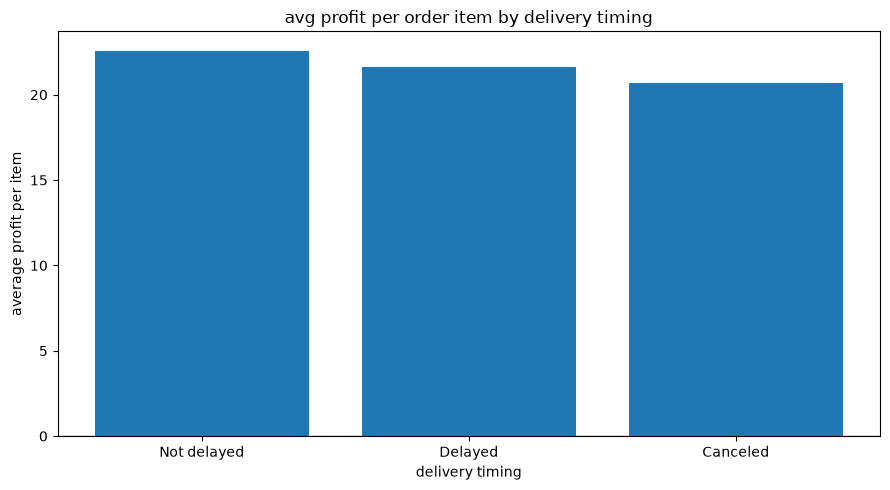

In [6]:
profit_plot = profit_by_timing.sort_values(
    "avg_profit_per_item", ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    profit_plot["delivery_timing"],
    profit_plot["avg_profit_per_item"]
)

plt.title("avg profit per order item by delivery timing")
plt.xlabel("delivery timing")
plt.ylabel("average profit per item")
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show

not delayed tertinggi 22.88, delayed kedua tertinggi 21,62 dan canceled paling rendah 20,70.

In [7]:
# negative profit validation
profit_by_category = (
    df.groupby(["Category Name", "delivery_timing"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit_per_item=("Order Profit Per Order", "mean"),
        negative_profit_items=("Order Profit Per Order",lambda s: (s < 0).sum())
    ).reset_index()
)
profit_by_category["negative_profit_pct"] = (profit_by_category["negative_profit_items"]/ profit_by_category["total_items"]* 100)
display(profit_by_category.sort_values(["Category Name", "delivery_timing"]).round(2))


,Category Name,delivery_timing,total_items,avg_profit_per_item,negative_profit_items,negative_profit_pct
0,Accessories,Canceled,83,10.74,15,18.07
1,Accessories,Delayed,1014,9.32,180,17.75
2,Accessories,Not delayed,683,9.22,124,18.16
3,As Seen on TV!,Canceled,2,-367.04,1,50.00
4,As Seen on TV!,Delayed,39,-2.73,11,28.21
...,...,...,...,...,...,...
144,Women's Clothing,Delayed,367,31.57,58,15.80
145,Women's Clothing,Not delayed,264,27.05,47,17.80
146,Women's Golf Clubs,Canceled,11,-31.24,3,27.27
147,Women's Golf Clubs,Delayed,97,36.90,16,16.49


Not delayed rata rata profit per item 22,58, delayed rata rata profit per item 21,62, canceled rata rata profit per item 20,70

In [8]:
# lowest average profit
category_profit_summary = (
    df.groupby("Category Name")
    .agg(
        total_items=("Order Item Id", "count"),
        total_profit=("Order Profit Per Order", "sum"),
        avg_profit_per_item=("Order Profit Per Order", "mean"),
        negative_profit_items=("Order Profit Per Order",lambda s: (s < 0).sum())
    ).reset_index()
)

category_profit_summary["negative_profit_pct"] = (category_profit_summary["negative_profit_items"]/ category_profit_summary["total_items"]* 100)

display(category_profit_summary.sort_values("avg_profit_per_item").round(2))


,Category Name,total_items,total_profit,avg_profit_per_item,negative_profit_items,negative_profit_pct
7,CDs,271,383.85,1.42,36,13.28
43,Toys,529,900.71,1.70,82,15.50
5,Books,405,883.01,2.18,78,19.26
41,Strength Training,111,332.31,2.99,18,16.22
45,Video Games,838,2717.52,3.24,181,21.60
24,Golf Balls,1475,8342.67,5.66,263,17.83
37,Pet Supplies,492,3589.26,7.30,104,21.14
2,Baby,207,1525.03,7.37,34,16.43
22,Golf Apparel,441,3496.31,7.93,88,19.95
44,Trade-In,974,7915.37,8.13,177,18.17


CDs rata rata profit terendah 1,42 per item diikuti toys 1,70 dan book sebesar 2.18,
Computer rata rata profit tertinggi 157,59 dengan total 442 item, nilai tinggi tapi volume kategory lebih kecil dibanding fishing atau cleats.
fishing total profit terbesar 756,220,77 dari 17,325 item 

In [9]:

category_timing_comparison = (
    df.groupby(["Category Name", "delivery_timing"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)


category_counts = (
    category_timing_comparison
    .pivot(
        index="Category Name",
        columns="delivery_timing",
        values="total_items"
    )
)

required_statuses = ["Delayed", "Not delayed", "Canceled"]

eligible_categories = category_counts[category_counts[required_statuses].ge(100).all(axis=1)].index

comparison = category_timing_comparison[category_timing_comparison["Category Name"].isin(eligible_categories)]

comparison_pivot = comparison.pivot(index="Category Name",columns="delivery_timing",values="avg_profit")

comparison_pivot["delayed_vs_not_delayed_diff"] = (comparison_pivot["Delayed"]- comparison_pivot["Not delayed"])

display(comparison_pivot.sort_values("delayed_vs_not_delayed_diff").round(2))


delivery_timing,Canceled,Delayed,Not delayed,delayed_vs_not_delayed_diff
Category Name,,,,
Camping & Hiking,30.70,29.18,33.76,-4.58
Cardio Equipment,37.15,29.01,32.20,-3.19
Fishing,33.76,43.05,45.48,-2.43
Women's Apparel,17.50,15.93,17.54,-1.61
Indoor/Outdoor Games,19.38,16.09,16.75,-0.66
Men's Footwear,15.45,13.74,14.23,-0.49
Cleats,19.29,19.99,20.45,-0.46
Electronics,18.04,12.96,12.41,0.55
Water Sports,24.49,21.07,20.35,0.72


Camping & hiking profit rata rata item delayed 29.18 sedangkan not delayed 33,76 . Cardio equipment delayed 29,01 not delayed 32.20.  Fishing delayed 43.05 sedangkan not delayed 45.48. Electronics delayed 12,96 not delayed 12,41

In [10]:
# Profit summary by shipment status
profit_comparison = (
    df.groupby("delivery_timing")
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean"),
        median_profit=("Order Profit Per Order", "median"),
        negative_profit_items=(
            "Order Profit Per Order",lambda x: (x < 0).sum()
        )
    ).reset_index()
)

profit_comparison["negative_profit_pct"] = (profit_comparison["negative_profit_items"]/ profit_comparison["total_items"] * 100).round(2)

display(profit_comparison.round(2))

,delivery_timing,total_items,avg_profit,median_profit,negative_profit_items,negative_profit_pct
0,Canceled,7754,20.70,31.57,1489,19.20
1,Delayed,98977,21.62,31.43,18553,18.74
2,Not delayed,73788,22.58,31.68,13742,18.62


Rata rata delayed item adalah 21,62, sedangkan not delayed 22,58 selisih 0.96 lebih tinggi dibanding delayed 

In [11]:
# average profit difference between Delayed and Not delayed items
category_profit = (
    df[df["delivery_timing"].isin(["Delayed", "Not delayed"])]
    .groupby(["Category Name", "delivery_timing"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

category_comparison = category_profit.pivot(
    index="Category Name",
    columns="delivery_timing",
    values="avg_profit"
)

category_comparison["profit_difference"] = (category_comparison["Delayed"]- category_comparison["Not delayed"])

display(category_comparison.sort_values("profit_difference").round(2))

delivery_timing,Delayed,Not delayed,profit_difference
Category Name,,,
Basketball,-4.07,76.32,-80.39
As Seen on TV!,-2.73,57.59,-60.32
Strength Training,-22.33,37.17,-59.50
Golf Bags & Carts,23.76,42.75,-18.99
Hunting & Shooting,7.68,22.52,-14.84
Consumer Electronics,25.88,38.56,-12.68
DVDs,11.74,20.64,-8.89
Baby,3.50,11.79,-8.29
Boxing & MMA,17.48,22.97,-5.49


Basketball memiliki selisih -80,39 as seen on tv! dan strength training -59,50. Sebaliknya beberapa kategori seperti garden , health dan beauty memiliki profit rata rata lebih tinggi pada item delayed. 


In [12]:
# Calculate the number of items and average profit per category/status
category_check = (
    df[df["delivery_timing"].isin(["Delayed", "Not delayed"])]
    .groupby(["Category Name", "delivery_timing"])
    .agg(
        item_count=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean"),
        median_profit=("Order Profit Per Order", "median"),
        std_profit=("Order Profit Per Order", "std")
    ).reset_index()
)

category_pivot = category_check.pivot(
    index="Category Name",
    columns="delivery_timing",
    values=["item_count", "avg_profit", "median_profit", "std_profit"]
)


category_pivot.columns = [f"{metric}_{timing.replace(' ', '_')}"for metric, timing in category_pivot.columns]
category_pivot = category_pivot.reset_index()
category_pivot = category_pivot[(category_pivot["item_count_Delayed"] >= 100)& (category_pivot["item_count_Not_delayed"] >= 100)].copy()
category_pivot["profit_difference"] = (category_pivot["avg_profit_Delayed"]- category_pivot["avg_profit_Not_delayed"])

display(
    category_pivot.sort_values("profit_difference")
    [[
        "Category Name",
        "item_count_Delayed",
        "item_count_Not_delayed",
        "avg_profit_Delayed",
        "avg_profit_Not_delayed",
        "profit_difference",
        "median_profit_Delayed",
        "median_profit_Not_delayed"
    ]].round(2)
)

,Category Name,item_count_Delayed,item_count_Not_delayed,avg_profit_Delayed,avg_profit_Not_delayed,profit_difference,median_profit_Delayed,median_profit_Not_delayed
29,Hunting & Shooting,247.0,177.0,7.68,22.52,-14.84,12.48,20.47
14,Consumer Electronics,238.0,171.0,25.88,38.56,-12.68,62.17,62.33
16,DVDs,259.0,200.0,11.74,20.64,-8.89,35.05,39.76
6,Boxing & MMA,238.0,164.0,17.48,22.97,-5.49,31.34,30.72
9,Camping & Hiking,7487.0,5670.0,29.18,33.76,-4.58,70.98,72.54
25,Golf Gloves,602.0,427.0,11.57,15.66,-4.09,12.34,12.27
32,Lacrosse,206.0,123.0,11.00,14.88,-3.88,15.30,14.06
28,Hockey,329.0,259.0,8.46,12.30,-3.84,10.47,10.78
36,Music,248.0,169.0,32.27,36.04,-3.76,63.03,61.90
10,Cardio Equipment,6805.0,5143.0,29.01,32.20,-3.19,44.64,46.06


Not delayed memiliki rata rata profit tertinggi yaitu 22.58 per item. Delayed item rata rata profit 21,62. Canceled rata rata profit paling rendah 20.70 dan presentase item dengan profit negatif tertinggi 19.20%. Hunting & shooting dan customer electronics menunjukkan rata rata profit lebih rendah pada item delayed. Health and beauty dan garden justru menunjukkan pola sebaliknya

In [13]:
# Aggregation of delivery performance by month
monthly_delivery = (
    df.groupby("order_year_month")
    .agg(
        total_items=("Order Item Id", "count"),
        delayed_items=("is_delayed", "sum"),
        canceled_items=("is_canceled", "sum"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

monthly_delivery["delayed_rate"] = (monthly_delivery["delayed_items"]/ monthly_delivery["total_items"] * 100)

monthly_delivery["canceled_rate"] = (monthly_delivery["canceled_items"]/ monthly_delivery["total_items"] * 100)

display(monthly_delivery.head())
display(monthly_delivery.tail())

,order_year_month,total_items,delayed_items,canceled_items,avg_profit,delayed_rate,canceled_rate
0,2015-01,5322,2880,208,20.980973,54.114994,3.908305
1,2015-02,4729,2594,242,20.964403,54.853034,5.117361
2,2015-03,5362,2936,235,21.219360,54.755688,4.382693
3,2015-04,5126,2760,211,21.085384,53.843153,4.116270
4,2015-05,5357,2951,270,20.934833,55.086802,5.040134


,order_year_month,total_items,delayed_items,canceled_items,avg_profit,delayed_rate,canceled_rate
32,2017-09,5189,2814,258,23.600384,54.230102,4.972056
33,2017-10,2255,1210,86,50.309166,53.658537,3.813747
34,2017-11,2055,1132,99,32.988443,55.085158,4.817518
35,2017-12,2124,1172,93,30.997001,55.178908,4.378531
36,2018-01,2123,1195,86,15.940598,56.288271,4.050871


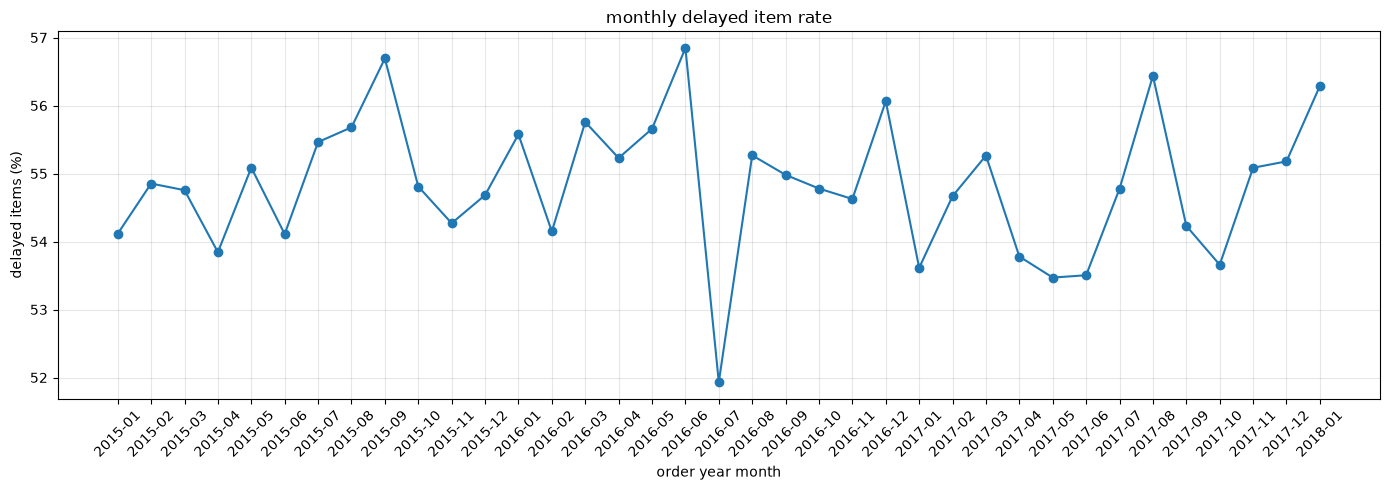

In [14]:
#visualization of delay trends

plt.figure(figsize=(14,5))

plt.plot(
    monthly_delivery["order_year_month"],
    monthly_delivery["delayed_rate"],
    marker="o"
)

plt.title("monthly delayed item rate")
plt.xlabel("order year month")
plt.ylabel("delayed items (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Tingkat keterlambatan relatif tinggi dan berfluktuasi dari bulan ke bulan . Juli 2016 tingkat keterlambatan turun ke sekitar 51,94% namun penurunan tajam ini hanya berlangsung sesaat karena bulan berikutnya keterlambatan kembali meningkat. Tepat sebelum penurunan tajam terjadi puncak tertinggi tingkat keterlambatan pada juni 2016. diluar penurunan ekstrim tersebut tingkat keterlambatan umumnya berada di kisaran 53-57% 

In [15]:
# Month with the highest & lowest delayed rate & # Check for the largest volume change
display(
    monthly_delivery.nlargest(5, "delayed_rate")[
        [
            "order_year_month",
            "total_items",
            "delayed_items",
            "delayed_rate",
            "avg_profit"
        ]
    ].round(2)
)

display(
    monthly_delivery.nsmallest(5, "delayed_rate")[
        [
            "order_year_month",
            "total_items",
            "delayed_items",
            "delayed_rate",
            "avg_profit"
        ]
    ].round(2)
)
monthly_delivery["item_change_pct"] = (monthly_delivery["total_items"].pct_change() * 100)

display(monthly_delivery.assign(item_change_pct=monthly_delivery["item_change_pct"].round(2)).sort_values("item_change_pct").head(5).round(2))

,order_year_month,total_items,delayed_items,delayed_rate,avg_profit
17,2016-06,5054,2873,56.85,20.62
8,2015-09,5140,2914,56.69,22.08
31,2017-08,5305,2994,56.44,24.79
36,2018-01,2123,1195,56.29,15.94
23,2016-12,5269,2954,56.06,19.93


,order_year_month,total_items,delayed_items,delayed_rate,avg_profit
18,2016-07,5305,2755,51.93,22.61
28,2017-05,5317,2843,53.47,21.63
29,2017-06,4951,2649,53.50,22.30
24,2017-01,5217,2797,53.61,22.01
33,2017-10,2255,1210,53.66,50.31


,order_year_month,total_items,delayed_items,canceled_items,avg_profit,delayed_rate,canceled_rate,item_change_pct
33,2017-10,2255,1210,86,50.31,53.66,3.81,-56.54
1,2015-02,4729,2594,242,20.96,54.85,5.12,-11.14
34,2017-11,2055,1132,99,32.99,55.09,4.82,-8.87
13,2016-02,4894,2650,211,17.74,54.15,4.31,-7.96
29,2017-06,4951,2649,221,22.30,53.50,4.46,-6.88


Tingkat keterlambatan tertinggi terjadi pada juni 2016 di 56,85% menjadi 51,93% pada juni 2016. Jumlah item justru naik dari 5,054 menjadi 5,305. Pada periode yang sama, rata-rata profit per item naik dari sekitar 23,60 menjadi 50,31.

In [16]:
# examining the October 2017 anomaly
period_check = df[df["order_year_month"].isin(["2017-09", "2017-10", "2017-11"])].copy()

category_check = (
    period_check
    .groupby(["order_year_month", "Category Name"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

top_categories = (
    category_check
    .sort_values(
        ["order_year_month", "total_items"],
        ascending=[True, False]
    ).groupby("order_year_month").head(10)
)

display(top_categories)

,order_year_month,Category Name,total_items,avg_profit
6,2017-09,Cleats,730,27.873397
17,2017-09,Men's Footwear,662,11.914260
24,2017-09,Women's Apparel,641,18.595757
7,2017-09,Fishing,566,43.028198
14,2017-09,Indoor/Outdoor Games,553,19.762423
23,2017-09,Water Sports,512,23.352031
4,2017-09,Camping & Hiking,436,32.874243
5,2017-09,Cardio Equipment,380,21.113368
19,2017-09,Shop By Sport,328,12.816951
15,2017-09,Kids' Golf Clubs,103,35.313106


Keterlambatan pengiriman masih tinggi, delayed item rate dikisaran 52-57% selama sebagian besar periode Januari 2015–Januari 2018. Tertinggi juni 2016 56,85% terendah juli 2016 51,93%. januari 56,29%

In [17]:
# is the decline in volume distributed evenly or concentrated?
category_volume = (category_check.pivot(index="Category Name",columns="order_year_month",values="total_items").fillna(0))

category_volume["change_sep_oct"] = (category_volume["2017-10"]- category_volume["2017-09"])

display(category_volume.sort_values("change_sep_oct").head(10))

order_year_month,2017-09,2017-10,2017-11,change_sep_oct
Category Name,,,,
Cleats,730.0,37.0,0.0,-693.0
Men's Footwear,662.0,32.0,0.0,-630.0
Women's Apparel,641.0,27.0,0.0,-614.0
Fishing,566.0,17.0,0.0,-549.0
Indoor/Outdoor Games,553.0,25.0,0.0,-528.0
Water Sports,512.0,25.0,0.0,-487.0
Camping & Hiking,436.0,15.0,0.0,-421.0
Cardio Equipment,380.0,22.0,0.0,-358.0
Shop By Sport,328.0,9.0,0.0,-319.0


canceled = jumlah item 7,754 rata-rata profit per item 20,70 item dengan profit negatif 19,20%.
delayed = jumlah item 98,977 rata-rata profit per item 21,62 item dengan profit negatif 18,74%.
not delayed = jumlah item 73,788 rata-rata profit per item 22,58 item dengan profit negatif 18,62%.

In [18]:
# temporal data quality validation
monthly_check = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Item Id", "size"),
        unique_orders=("Order Id", "nunique"),
        unique_products=("Product Name", "nunique"),
        unique_categories=("Category Name", "nunique"),
        unique_regions=("Order Region", "nunique"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

display(monthly_check[monthly_check["order_year_month"].between("2017-07", "2018-01")])

region_month_check = (
    df[df["order_year_month"].isin(["2017-09", "2017-10", "2017-11"])]
    .groupby(["order_year_month", "Order Region"])
    .agg(
        total_items=("Order Item Id", "size"),
        unique_orders=("Order Id", "nunique")
    ).reset_index()
)

display(region_month_check.sort_values(["Order Region", "order_year_month"]))

,order_year_month,total_rows,unique_orders,unique_products,unique_categories,unique_regions,avg_profit
30,2017-07,5318,1776,42,24,3,21.253610
31,2017-08,5305,1768,42,24,3,24.788155
32,2017-09,5189,1723,53,26,3,23.600384
33,2017-10,2255,2101,20,20,3,50.309166
34,2017-11,2055,2055,8,8,7,32.988443
35,2017-12,2124,2124,14,14,4,30.997001
36,2018-01,2123,2123,10,10,4,15.940598


,order_year_month,Order Region,total_items,unique_orders
6,2017-11,Eastern Asia,377,377
0,2017-09,Northern Europe,1104,365
3,2017-10,Northern Europe,460,434
7,2017-11,Northern Europe,168,168
8,2017-11,Oceania,371,371
9,2017-11,South Asia,256,256
10,2017-11,Southeast Asia,369,369
1,2017-09,Southern Europe,1058,360
4,2017-10,Southern Europe,433,422
11,2017-11,Southern Europe,144,144


Dari september ke oktober jumlah baris turun 56,54%, lalu tetap rendah sampai Januari 2018. Pada juli-september ada sekitar 3 baris perorder secara rata rata. Pada oktober turun sekitar 1,07 baris per order. Jumlah kategory turun dari 26 pada september jadi 20 pada oktober dan 8 pada november, jumlah wilayah justru meningkat dari 3 menjadi 7 pada november 

In [19]:
# average items per order each month
monthly_grain = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Item Id", "size"),
        unique_items=("Order Item Id", "nunique"),
        unique_orders=("Order Id", "nunique")
    ).reset_index()
)

monthly_grain["rows_per_order"] = (monthly_grain["total_rows"] /monthly_grain["unique_orders"])

monthly_grain["items_per_order"] = (monthly_grain["unique_items"] /monthly_grain["unique_orders"])

display(monthly_grain[monthly_grain["order_year_month"].between("2017-07", "2018-01")].round(2))

# does the order still contain many items
items_per_order = (
    df.groupby("Order Id")
    .agg(
        item_rows=("Order Item Id", "size"),
        unique_item_ids=("Order Item Id", "nunique"),
        order_month=("order_year_month", "first")
    ).reset_index()
)

order_structure = (
    items_per_order.groupby("order_month")
    .agg(
        unique_orders=("Order Id", "nunique"),
        avg_item_rows=("item_rows", "mean"),
        median_item_rows=("item_rows", "median"),
        orders_with_multiple_rows=(
            "item_rows",
            lambda s: (s > 1).sum()
        )
    ).reset_index()
)

display(order_structure[order_structure["order_month"].between("2017-07", "2018-01")].round(2))

# validation of date and completeness of the period
date_check = (
    df.groupby("order_year_month")
    .agg(
        min_order_date=("order_date", "min"),
        max_order_date=("order_date", "max"),
        total_rows=("Order Item Id", "size")
    ).reset_index()
)

display(date_check[date_check["order_year_month"].between("2017-07", "2018-01")])

,order_year_month,total_rows,unique_items,unique_orders,rows_per_order,items_per_order
30,2017-07,5318,5318,1776,2.99,2.99
31,2017-08,5305,5305,1768,3.00,3.00
32,2017-09,5189,5189,1723,3.01,3.01
33,2017-10,2255,2255,2101,1.07,1.07
34,2017-11,2055,2055,2055,1.00,1.00
35,2017-12,2124,2124,2124,1.00,1.00
36,2018-01,2123,2123,2123,1.00,1.00


,order_month,unique_orders,avg_item_rows,median_item_rows,orders_with_multiple_rows
30,2017-07,1776,2.99,3.0,1436
31,2017-08,1768,3.00,3.0,1410
32,2017-09,1723,3.01,3.0,1355
33,2017-10,2101,1.07,1.0,63
34,2017-11,2055,1.00,1.0,0
35,2017-12,2124,1.00,1.0,0
36,2018-01,2123,1.00,1.0,0


,order_year_month,min_order_date,max_order_date,total_rows
30,2017-07,2017-07-01 00:00:00,2017-07-31 00:00:00,5318
31,2017-08,2017-08-01 00:00:00,2017-08-31 00:00:00,5305
32,2017-09,2017-09-01 00:00:00,2017-09-30 00:00:00,5189
33,2017-10,2017-10-01 00:00:00,2017-10-31 00:00:00,2255
34,2017-11,2017-11-01 00:00:00,2017-11-30 00:00:00,2055
35,2017-12,2017-12-01 00:00:00,2017-12-31 00:00:00,2124
36,2018-01,2018-01-01 00:00:00,2018-01-31 00:00:00,2123


In [20]:
# does this also apply to changes in the number of lines per order or other aspects?

monthly_check = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Item Id", "size"),
        unique_orders=("Order Id", "nunique"),
        unique_items=("Order Item Id", "nunique"),
        unique_products=("Product Name", "nunique"),
        unique_categories=("Category Name", "nunique"),
        unique_regions=("Order Region", "nunique"),
        min_order_date=("order_date", "min"),
        max_order_date=("order_date", "max")
    )
    .reset_index()
)

display(monthly_check.tail(12))

,order_year_month,total_rows,unique_orders,unique_items,unique_products,unique_categories,unique_regions,min_order_date,max_order_date
25,2017-02,4906,1614,4906,54,24,3,2017-02-01 00:00:00,2017-02-28 00:00:00
26,2017-03,5347,1782,5347,54,24,3,2017-03-01 00:00:00,2017-03-31 00:00:00
27,2017-04,5212,1739,5212,87,31,3,2017-04-01 00:00:00,2017-04-30 00:00:00
28,2017-05,5317,1763,5317,42,24,3,2017-05-01 00:00:00,2017-05-31 00:00:00
29,2017-06,4951,1676,4951,42,24,6,2017-06-01 00:00:00,2017-06-30 00:00:00
30,2017-07,5318,1776,5318,42,24,3,2017-07-01 00:00:00,2017-07-31 00:00:00
31,2017-08,5305,1768,5305,42,24,3,2017-08-01 00:00:00,2017-08-31 00:00:00
32,2017-09,5189,1723,5189,53,26,3,2017-09-01 00:00:00,2017-09-30 00:00:00
33,2017-10,2255,2101,2255,20,20,3,2017-10-01 00:00:00,2017-10-31 00:00:00
34,2017-11,2055,2055,2055,8,8,7,2017-11-01 00:00:00,2017-11-30 00:00:00


In [21]:
# Compare the periods before and after the change
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

df["period"] = np.select(
    [df["order_date"] < "2017-10-01",df["order_date"] < "2017-11-01",],
    ["Before Oct 2017","Oct 2017",],default="After Oct 2017",
)

audit_columns = [
    "Order Status",
    "Delivery Status",
    "Shipping Mode",
    "Market",
    "Order Region",
]

for col in audit_columns:
    print(f"\n--- {col} ---")
    display(
        pd.crosstab(
            df["period"],
            df[col],
            normalize="index"
        ).round(3) * 100
    )


--- Order Status ---


Order Status,CANCELED,CLOSED,COMPLETE,ON_HOLD,PAYMENT_REVIEW,PENDING,PENDING_PAYMENT,PROCESSING,SUSPECTED_FRAUD
period,,,,,,,,,
After Oct 2017,2.3,11.6,33.1,5.2,1.1,11.3,21.3,11.9,2.1
Before Oct 2017,2.0,10.8,32.9,5.4,1.0,11.2,22.1,12.1,2.3
Oct 2017,1.6,10.6,33.5,5.0,1.1,11.0,22.0,13.0,2.2



--- Delivery Status ---


Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
period,,,,
After Oct 2017,22.6,55.5,4.4,17.5
Before Oct 2017,23.0,54.8,4.3,17.8
Oct 2017,24.1,53.7,3.8,18.4



--- Shipping Mode ---


Shipping Mode,First Class,Same Day,Second Class,Standard Class
period,,,,
After Oct 2017,15.1,5.7,20.2,59.1
Before Oct 2017,15.4,5.4,19.5,59.7
Oct 2017,15.6,4.9,18.5,61.0



--- Market ---


Market,Africa,Europe,LATAM,Pacific Asia,USCA
period,,,,,
After Oct 2017,0.0,10.8,0.0,89.2,0.0
Before Oct 2017,6.8,27.5,30.0,20.7,15.0
Oct 2017,0.0,100.0,0.0,0.0,0.0



--- Order Region ---


Order Region,Canada,Caribbean,Central Africa,Central America,Central Asia,East Africa,East of USA,Eastern Asia,Eastern Europe,North Africa,...,South Asia,South of USA,Southeast Asia,Southern Africa,Southern Europe,US Center,West Africa,West Asia,West of USA,Western Europe
period,,,,,,,,,,,,,,,,,,,,,
After Oct 2017,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.9,0.0,0.0,...,17.8,0.0,27.8,0.0,2.3,0.0,0.0,0.0,0.0,5.9
Before Oct 2017,0.6,4.8,1.0,16.5,0.3,1.1,4.0,3.5,2.3,1.9,...,3.8,2.4,4.5,0.7,5.1,3.4,2.1,3.5,4.6,14.8
Oct 2017,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,19.2,0.0,0.0,0.0,0.0,60.4


In [22]:
# 1. Check the number of orders and items per month
monthly_audit = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Id", "size"),
        unique_orders=("Order Id", "nunique"),
        unique_customers=("Customer Id", "nunique"),
        unique_products=("Product Name", "nunique"),
        unique_markets=("Market", "nunique"),
    ).reset_index()
)

monthly_audit["rows_per_order"] = (monthly_audit["total_rows"]/ monthly_audit["unique_orders"])
display(monthly_audit.tail(12))


,order_year_month,total_rows,unique_orders,unique_customers,unique_products,unique_markets,rows_per_order
25,2017-02,4906,1614,1491,54,1,3.039653
26,2017-03,5347,1782,1674,54,1,3.000561
27,2017-04,5212,1739,1610,87,1,2.997125
28,2017-05,5317,1763,1654,42,1,3.015882
29,2017-06,4951,1676,1578,42,2,2.954057
30,2017-07,5318,1776,1662,42,1,2.994369
31,2017-08,5305,1768,1637,42,1,3.000566
32,2017-09,5189,1723,1620,53,1,3.011608
33,2017-10,2255,2101,2101,20,1,1.073298
34,2017-11,2055,2055,2055,8,2,1.000000


In [23]:

date_columns = ["order_date", "shipping_date"]

for col in date_columns:
    print(f"\n--- {col} ---")
    print("Tanggal kosong:", df[col].isna().sum())
    print("Tanggal minimum:", df[col].min())
    print("Tanggal maksimum:", df[col].max())



--- order_date ---
Tanggal kosong: 0
Tanggal minimum: 2015-01-01 00:00:00
Tanggal maksimum: 2018-01-31 00:00:00

--- shipping_date ---
Tanggal kosong: 0
Tanggal minimum: 2015-01-03 00:00:00
Tanggal maksimum: 2018-02-06 00:00:00


In [24]:

# Check how many line items are in each order
items_per_order = (df.groupby("Order Id").size().rename("item_rows").reset_index())

print("Distribution of the number of rows per order:")
display(items_per_order["item_rows"].value_counts().sort_index().rename_axis("item_rows").reset_index(name="number_of_orders"))

print("\nSummary of the number of lines per order:")
display(items_per_order["item_rows"].describe())


Distribution of the number of rows per order:


,item_rows,number_of_orders
0,1,19850
1,2,11447
2,3,11398
3,4,11704
4,5,11353



Summary of the number of lines per order:


count    65752.000000
mean         2.745453
std          1.478363
min          1.000000
25%          1.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: item_rows, dtype: float64

In [25]:

# Calculate the number of rows for each order per month
order_monthly = (df.groupby(["order_year_month", "Order Id"]).size().rename("item_rows").reset_index())

monthly_item_distribution = pd.crosstab(
    order_monthly["order_year_month"],
    order_monthly["item_rows"],
    normalize="index"
).mul(100).round(2)

display(monthly_item_distribution.tail(12))


item_rows,1,2,3,4,5
order_year_month,,,,,
2017-02,19.64,19.02,19.21,22.00,20.14
2017-03,20.48,19.75,18.97,20.82,19.98
2017-04,20.07,21.39,18.63,18.57,21.33
2017-05,19.51,19.34,20.82,20.70,19.63
2017-06,21.90,19.87,18.44,20.53,19.27
2017-07,19.14,22.07,19.43,18.92,20.44
2017-08,20.25,19.74,19.46,20.81,19.74
2017-09,21.36,18.51,19.09,19.67,21.36
2017-10,97.00,0.81,0.81,0.62,0.76


In [26]:

check_columns = ["order_date","Market","Order Status","Delivery Status","Shipping Mode",]

order_consistency = (df.groupby("Order Id")[check_columns].nunique(dropna=False))

for col in check_columns:
    inconsistent = order_consistency[col].gt(1).sum()
    print(f"{col}: {inconsistent:,} order has more than one value")


order_date: 0 order has more than one value
Market: 0 order has more than one value
Order Status: 0 order has more than one value
Delivery Status: 0 order has more than one value
Shipping Mode: 0 order has more than one value


In [27]:
profit_check = (
    df.groupby("Order Id")["Order Profit Per Order"]
    .nunique(dropna=False)
)

print("Order dengan nilai profit berbeda antarbaris:",
      profit_check.gt(1).sum())

Order dengan nilai profit berbeda antarbaris: 45902


In [28]:
# Ambil contoh order yang memiliki nilai profit berbeda
inconsistent_ids = profit_check[profit_check > 1].index[:5]

display(
    df.loc[
        df["Order Id"].isin(inconsistent_ids),
        ["Order Id", "Product Name", "Order Profit Per Order",
         "Order Item Profit Ratio", "Sales", "Order Item Quantity"]
    ].sort_values("Order Id")
)

,Order Id,Product Name,Order Profit Per Order,Order Item Profit Ratio,Sales,Order Item Quantity
77011,2,Pelican Sunstream 100 Kayak,91.180000,0.47,199.990005,1
87884,2,Nike Men's CJ Elite 2 TD Football Cleat,36.470001,0.34,129.990005,1
109322,2,Nike Men's Dri-FIT Victory Golf Polo,68.250000,0.30,250.000000,5
63764,4,Team Golf New England Patriots Putter Grip,4.100000,0.10,49.980000,2
95938,4,Nike Men's Dri-FIT Victory Golf Polo,60.270000,0.49,150.000000,3
96131,4,Perfect Fitness Perfect Rip Deck,26.129999,0.09,299.950012,5
114915,4,O'Brien Men's Neoprene Life Vest,33.590000,0.21,199.919998,4
20305,5,Nike Men's CJ Elite 2 TD Football Cleat,34.939999,0.32,129.990005,1
20680,5,Diamondback Women's Serene Classic Comfort Bi,109.550003,0.44,299.980011,1
114914,5,O'Brien Men's Neoprene Life Vest,9.380000,0.11,99.959999,2


In [29]:
profit_df = df[
    ~df["is_canceled"]
    & df["delivery_timing"].isin(["Delayed", "Not delayed"])
].copy()

profit_summary = (
    profit_df
    .groupby("delivery_timing")["Order Profit Per Order"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(profit_summary)

,count,mean,median,std,min,max
delivery_timing,,,,,,
Delayed,98977,21.62,31.43,105.47,-4274.98,911.8
Not delayed,73788,22.58,31.68,102.84,-3366.00,864.0


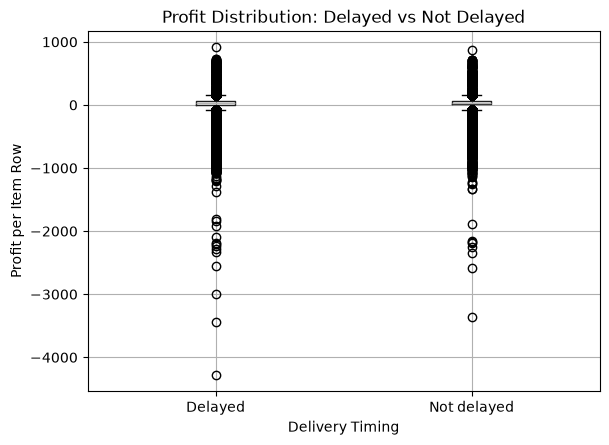

In [30]:
import matplotlib.pyplot as plt

profit_df.boxplot(
    column="Order Profit Per Order",
    by="delivery_timing"
)

plt.title("Profit Distribution: Delayed vs Not Delayed")
plt.suptitle("")
plt.xlabel("Delivery Timing")
plt.ylabel("Profit per Item Row")
plt.show()

In [31]:

category_profit = (
    profit_df
    .groupby(["Category Name", "delivery_timing"])
    ["Order Profit Per Order"]
    .agg(["mean", "count"])
    .reset_index()
)

category_comparison = category_profit.pivot(
    index="Category Name",
    columns="delivery_timing",
    values="mean"
)

category_counts = category_profit.pivot(
    index="Category Name",
    columns="delivery_timing",
    values="count"
)

category_comparison["profit_difference"] = (
    category_comparison["Delayed"]
    - category_comparison["Not delayed"]
)

category_comparison["delayed_count"] = category_counts["Delayed"]
category_comparison["not_delayed_count"] = category_counts["Not delayed"]

display(
    category_comparison
    .sort_values("profit_difference")
    .round(2)
)


delivery_timing,Delayed,Not delayed,profit_difference,delayed_count,not_delayed_count
Category Name,,,,,
Basketball,-4.07,76.32,-80.39,37,27
As Seen on TV!,-2.73,57.59,-60.32,39,27
Strength Training,-22.33,37.17,-59.50,64,45
Golf Bags & Carts,23.76,42.75,-18.99,42,19
Hunting & Shooting,7.68,22.52,-14.84,247,177
Consumer Electronics,25.88,38.56,-12.68,238,171
DVDs,11.74,20.64,-8.89,259,200
Baby,3.50,11.79,-8.29,109,89
Boxing & MMA,17.48,22.97,-5.49,238,164


In [33]:
from scipy.stats import mannwhitneyu

delayed_profit = profit_df.loc[
    profit_df["delivery_timing"] == "Delayed",
    "Order Profit Per Order"
].dropna()

not_delayed_profit = profit_df.loc[
    profit_df["delivery_timing"] == "Not delayed",
    "Order Profit Per Order"
].dropna()

stat, p_value = mannwhitneyu(
    delayed_profit,
    not_delayed_profit,
    alternative="two-sided"
)

print(f"Mann-Whitney U statistic: {stat:.2f}")
print(f"P-value: {p_value:.6g}")

Mann-Whitney U statistic: 3637088323.50
P-value: 0.155373
